In [14]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))


from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import classification_plots

In [2]:
COLUMNS = "admet_columns.json"

In [5]:
df = DataManager(path='admet/mutagenicity').dataset

with open(COLUMNS, 'r') as f:
    data = json.load(f)

df = df[data['columns']]
df

,mol_weight,logp,tpsa,num_h_donors,num_h_acceptors,num_rotatable_bonds,num_aromatic_rings,num_rings,num_heavy_atoms,fraction_csp3,...,fp_1015,fp_1016,fp_1017,fp_1018,fp_1019,fp_1020,fp_1021,fp_1022,fp_1023,label
0,342.310,5.5536,86.28,0,4,2,5,5,26,0.000000,...,0,0,0,0,0,0,0,0,0,1
1,301.345,5.3710,43.14,0,2,1,4,5,23,0.200000,...,0,0,0,0,0,0,0,0,0,1
2,646.614,6.3494,134.00,2,6,0,11,11,50,0.000000,...,0,0,0,0,0,0,0,0,0,0
3,157.133,-2.6069,120.62,3,3,3,0,0,11,0.250000,...,0,0,0,0,0,0,0,0,0,1
4,138.086,-1.0222,94.93,1,2,0,0,1,10,0.000000,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2115,223.231,3.9012,43.14,0,2,1,3,3,17,0.000000,...,0,0,0,0,0,0,0,0,0,1
2116,147.432,2.0714,0.00,0,0,2,0,0,6,1.000000,...,0,0,0,0,0,0,1,0,0,1
2117,266.296,2.3898,57.53,2,3,0,2,4,20,0.235294,...,0,0,0,0,1,0,0,0,0,1
2118,390.564,4.6861,74.60,2,3,4,0,4,28,0.916667,...,0,0,0,0,1,0,0,0,0,0


In [10]:
fp_cols = [col for col in df.columns if col.startswith('fp_')]
unique_cols = df[fp_cols].nunique()
constant_cols = unique_cols[unique_cols == 1]

# exclude_column(path=COLUMNS, col_name="herg_exclusion", col=list(constant_cols.index))
# df = df.drop(columns=constant_cols.index)
# constant_cols

In [11]:
null = df.isnull().sum().sum()
null

np.int64(0)

In [13]:
X = df.drop(columns='label')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=25)
len(df.columns)

1041

In [17]:
ros = RandomOverSampler()
X_train, y_train = ros.fit_resample(X_train, y_train)

In [22]:
model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [None, 5, 10, 20, 30, 50],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
    "max_samples": [None, 0.6, 0.8, 1.0]
}

search = RandomizedSearchCV(
    model,
    param_distributions=param_grid,
    n_iter=50,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)



{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_samples': None, 'max_features': 0.2, 'max_depth': 30}
0.8714023072864376


In [23]:
best_model = search.best_estimator_

# best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [24]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.76      0.78      0.77       186
           1       0.83      0.80      0.81       238

    accuracy                           0.79       424
   macro avg       0.79      0.79      0.79       424
weighted avg       0.80      0.79      0.80       424

[[146  40]
 [ 47 191]]


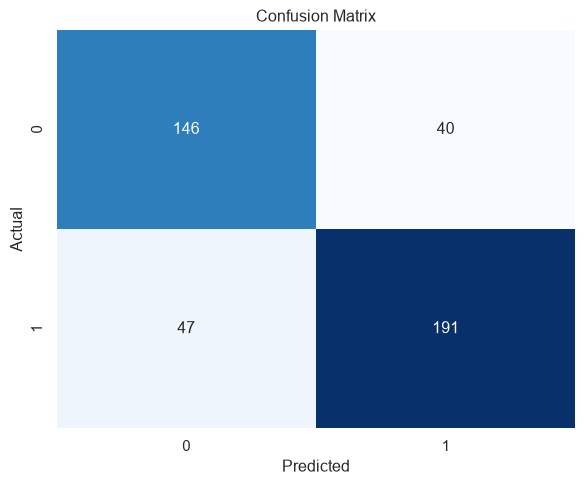

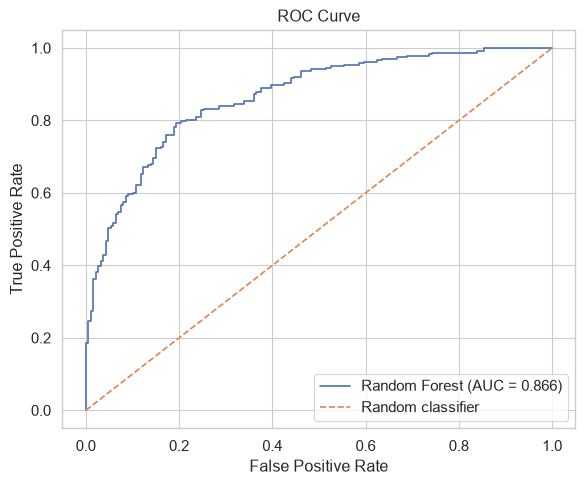

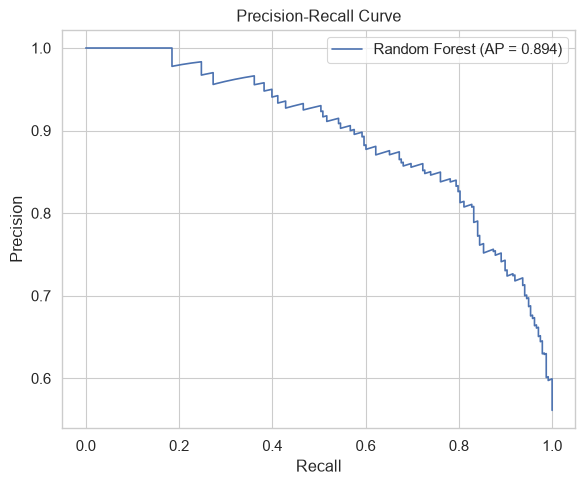

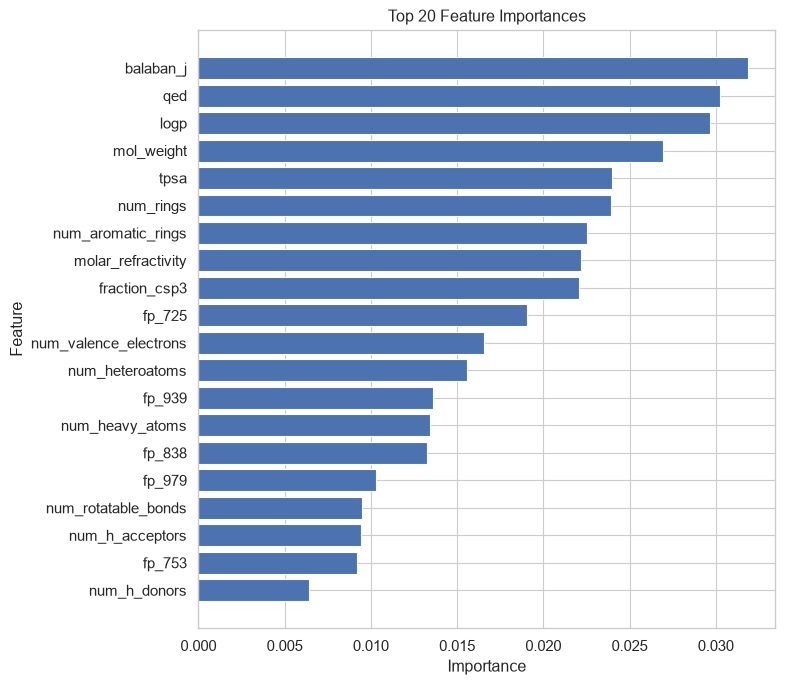

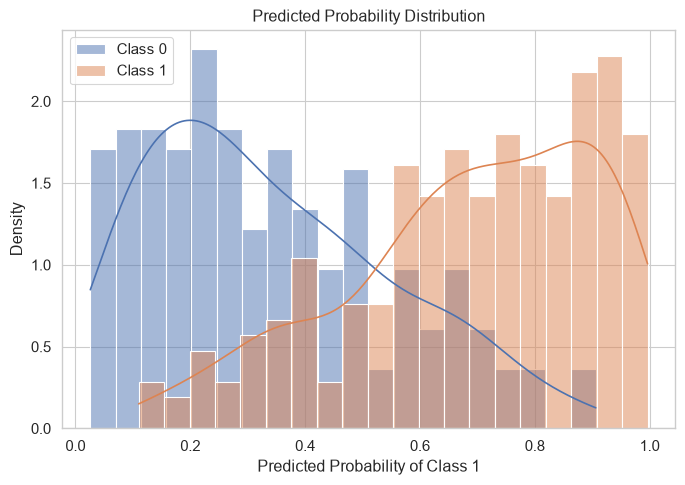

In [26]:
classification_plots(best_model, X_test, y_test, X_train.columns)